# Healthcare Billing Prediction Using Python and Logistic Regression

## Project Overview

This project analyzes 900 healthcare billing records to explore patient characteristics associated with high and low billing amounts. It uses Logistic Regression to classify patients into high- and low-billing categories and evaluate the model's predictive performance.

## Business Objectives

- Explore healthcare billing patterns across patient characteristics.
- Identify relationships between age, gender, medical conditions, insurance providers, and billing categories.
- Clean and prepare healthcare data for machine learning.
- Build and evaluate a Logistic Regression classification model.
- Compare model performance against a majority-class baseline.
- Communicate findings, model limitations, and potential business applications.

## Tools and Technologies

- **Python:** Data analysis and machine learning.
- **Pandas and NumPy:** Data manipulation and numerical calculations.
- **Matplotlib and Seaborn:** Data visualization.
- **Scikit-learn:** Data preprocessing, Logistic Regression, and model evaluation.
- **Jupyter Notebook:** Analysis documentation and reporting.

## Dataset Description

The analysis uses 900 healthcare billing records after removing observations with missing billing amounts.

The prediction model uses four patient characteristics: Age, Gender, Medical Condition, and Insurance Provider.

The target variable, `High_Billing`, categorizes patients based on whether their billing amount exceeds the dataset's median billing amount.

The dataset is used for educational and portfolio practice and does not establish verified real-world hospital billing patterns.

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [2]:
df = pd.read_csv('healthcare_billing_messy_practice (1).csv')

In [3]:
df.head()

,Patient_ID,Name,Age,Gender,Medical_Condition,Date_of_Admission,Doctor,Hospital,Insurance_Provider,Billing_Amount,Admission_Type,Discharge_Date,Medication
0,P00522,Patient 0522,31.0,Male,Stroke,NaN,Dr. Smith,Central Hospital,Medicare,25397.56,Elective,2023-03-29,Atorvastatin
1,P00738,Patient 0738,88.0,Female,Hypertension,2024-02-25,Dr. Johnson,Northside Clinic,Medicaid,25486.49,Urgent,2024-03-14,Aspirin
2,P00741,Patient 0741,48.0,Female,NaN,2024-01-07,Dr. Patel,Central Hospital,Medicare,19129.23,Elective,2024-01-15,Aspirin
3,P00661,Patient 0661,57.0,Female,Hypertension,2025-06-03,Dr. Patel,Central Hospital,Aetna,18338.78,Emergency,2025-06-14,Aspirin
4,P00412,Patient 0412,48.0,Female,Arthritis,2023-11-02,Dr. Smith,Valley Medical,NaN,17091.34,Elective,2023-11-06,Aspirin


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Patient_ID          1000 non-null   object 
 1   Name                1000 non-null   object 
 2   Age                 942 non-null    float64
 3   Gender              1000 non-null   object 
 4   Medical_Condition   933 non-null    object 
 5   Date_of_Admission   922 non-null    object 
 6   Doctor              1000 non-null   object 
 7   Hospital            1000 non-null   object 
 8   Insurance_Provider  926 non-null    object 
 9   Billing_Amount      939 non-null    float64
 10  Admission_Type      1000 non-null   object 
 11  Discharge_Date      1000 non-null   object 
 12  Medication          1000 non-null   object 
dtypes: float64(2), object(11)
memory usage: 101.7+ KB


In [5]:
df.describe()

,Age,Billing_Amount
count,942.000000,939.000000
mean,53.279193,22644.523046
std,20.522753,7211.208143
min,18.000000,6309.520000
25%,35.000000,17149.705000
50%,52.500000,22236.680000
75%,70.000000,27130.375000
max,89.000000,45828.600000


In [6]:
df[df.isnull().any(axis=1)]

,Patient_ID,Name,Age,Gender,Medical_Condition,Date_of_Admission,Doctor,Hospital,Insurance_Provider,Billing_Amount,Admission_Type,Discharge_Date,Medication
0,P00522,Patient 0522,31.0,Male,Stroke,NaN,Dr. Smith,Central Hospital,Medicare,25397.56,Elective,2023-03-29,Atorvastatin
2,P00741,Patient 0741,48.0,Female,NaN,2024-01-07,Dr. Patel,Central Hospital,Medicare,19129.23,Elective,2024-01-15,Aspirin
4,P00412,Patient 0412,48.0,Female,Arthritis,2023-11-02,Dr. Smith,Valley Medical,NaN,17091.34,Elective,2023-11-06,Aspirin
8,P00860,Patient 0860,62.0,Male,NaN,NaN,Dr. Johnson,Valley Medical,NaN,19629.61,Urgent,2023-10-31,Albuterol
12,P00637,Patient 0637,46.0,Male,Asthma,2023-07-02,Dr. Patel,Central Hospital,Medicaid,NaN,Urgent,2023-07-09,Atorvastatin
...,...,...,...,...,...,...,...,...,...,...,...,...,...
994,P00072,Patient 0072,23.0,Female,Obesity,NaN,Dr. Patel,Central Hospital,UnitedHealthcare,17271.11,Elective,2024-12-22,Atorvastatin
995,P00107,Patient 0107,NaN,Female,Diabetes,2023-08-17,Dr. Johnson,Central Hospital,Medicaid,27646.18,Urgent,2023-09-02,Lisinopril
996,P00271,Patient 0271,59.0,Male,Hypertension,NaN,Dr. Kim,Valley Medical,Cigna,12025.38,Elective,2023-04-07,Metformin
998,P00436,Patient 0436,82.0,Female,Heart Disease,2025-01-28,Dr. Johnson,Central Hospital,Blue Cross,NaN,Urgent,2025-01-30,Lisinopril


### Checking Missing Values

In [7]:
df.isnull().sum()

Patient_ID             0
Name                   0
Age                   58
Gender                 0
Medical_Condition     67
Date_of_Admission     78
Doctor                 0
Hospital               0
Insurance_Provider    74
Billing_Amount        61
Admission_Type         0
Discharge_Date         0
Medication             0
dtype: int64

### Checking Duplicates

In [8]:
df.duplicated().sum()

40

### Dropping Duplicates

In [9]:
df=df.drop_duplicates()

### Confirm Duplicates Drop

In [10]:
df.duplicated().sum()

0

In [11]:
df.columns

Index(['Patient_ID', 'Name', 'Age', 'Gender', 'Medical_Condition',
       'Date_of_Admission', 'Doctor', 'Hospital', 'Insurance_Provider',
       'Billing_Amount', 'Admission_Type', 'Discharge_Date', 'Medication'],
      dtype='object')

### Data Cleaning: Missing Values and Data Types

This section prepares the dataset for analysis by converting Age and Billing_Amount to numeric values, removing records with missing billing amounts, and assigning an "unknown" category to missing medical conditions and insurance providers.

Missing Age values are preserved for imputation using training data during model preprocessing.

In [12]:
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')

In [13]:
df['Billing_Amount'] = pd.to_numeric(df['Billing_Amount'], errors='coerce')

df = df.dropna(subset=['Billing_Amount']).copy()

In [14]:
print("Total records:", df.shape[0])
print("Missing Billing Amount:", df['Billing_Amount'].isna().sum())
print("Missing Age:", df['Age'].isna().sum())

Total records: 900
Missing Billing Amount: 0
Missing Age: 52


In [15]:
df['Medical_Condition'] = df['Medical_Condition'].fillna('unknown')

In [16]:
df['Insurance_Provider'] = df['Insurance_Provider'].fillna('unknown')

### Convert String Date to Datetime

In [17]:
df[ 'Date_of_Admission'] = pd.to_datetime(df[ 'Date_of_Admission'])

In [18]:
df['Discharge_Date'] = pd.to_datetime(df['Discharge_Date'])

### Fill Missing Date of Admission Using Discharge Date Minus Median Hospital Stay

In [19]:
median_stay = (df['Discharge_Date'] - df['Date_of_Admission']).dt.days.median()

In [20]:
df['Date_of_Admission'] = df['Date_of_Admission'].fillna(df['Discharge_Date'] - pd.to_timedelta(median_stay, unit='D'))

In [21]:
df['Length_of_Stay'] = (df['Discharge_Date'] - df['Date_of_Admission']).dt.days


## Check the date calculations

In [22]:
print("Missing admission dates:", df['Date_of_Admission'].isna().sum())

print("Missing discharge dates:", df['Discharge_Date'].isna().sum())

print("Negative hospital stays:",
      (df['Length_of_Stay'] < 0).sum())

Missing admission dates: 0
Missing discharge dates: 0
Negative hospital stays: 0


### Define Billing Amount Threshold

In [23]:
threshold = df['Billing_Amount'].median()

In [24]:
threshold

22258.075

### Create Binary Target Column

In [25]:
df['High_Billing'] = (df['Billing_Amount'] > threshold).astype(int)

In [26]:
df['High_Billing'].value_counts(normalize=True)

1    0.5
0    0.5
Name: High_Billing, dtype: float64

## Verify

In [27]:
print("Billing threshold:", round(threshold, 2))
print("Total records:", len(df))
print("Low-billing patients:", (df['High_Billing'] == 0).sum())
print("High-billing patients:", (df['High_Billing'] == 1).sum())

Billing threshold: 22258.08
Total records: 900
Low-billing patients: 450
High-billing patients: 450


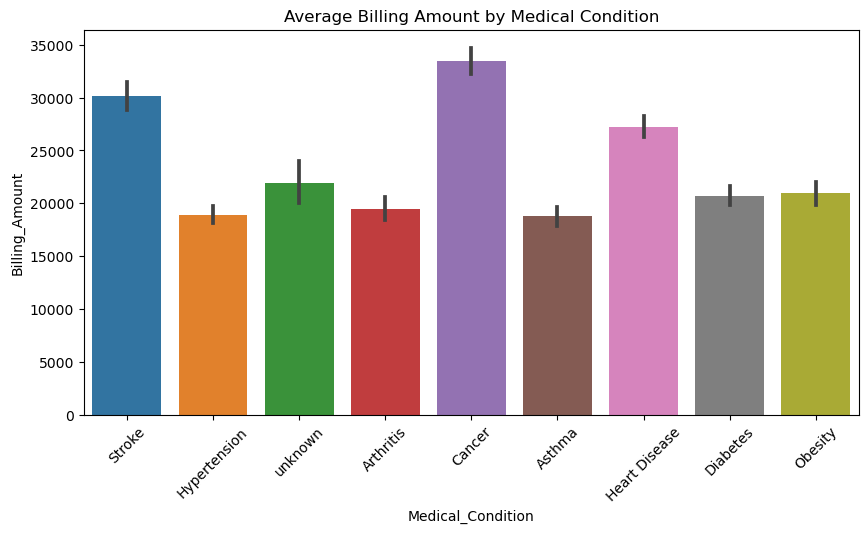

In [28]:
plt.figure(figsize=(10,5))
sns.barplot(data=df, x='Medical_Condition', y='Billing_Amount', estimator='mean')
plt.xticks(rotation=45)
plt.title('Average Billing Amount by Medical Condition')
plt.show()

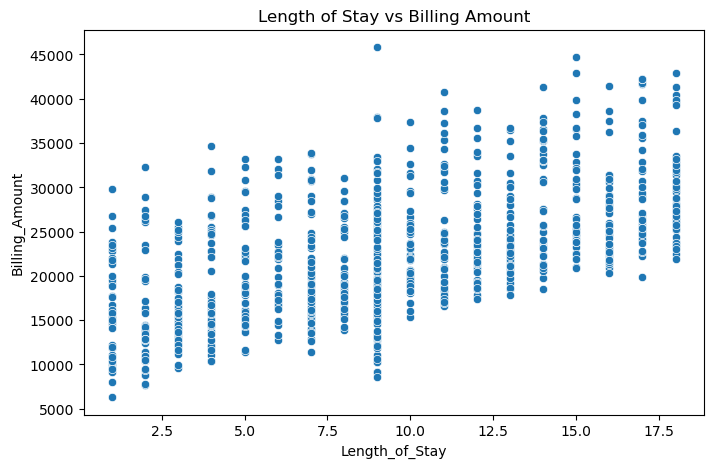

In [29]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df,x='Length_of_Stay',y='Billing_Amount')
plt.title('Length of Stay vs Billing Amount')
plt.show()

## Verify the Encoding

## Split features and target
We’ll split data into 70% training / 30% testing.

In [30]:

# Select predictors without target leakage
X = df.drop(
    columns=[
        'High_Billing',
        'Billing_Amount',
        'Patient_ID',
        'Name',
        'Date_of_Admission',
        'Discharge_Date',
        'Doctor',
        'Hospital',
        'Admission_Type',
        'Medication',
        'Length_of_Stay'
    ],
    errors='ignore'
).copy()

# Define target variable
y = df['High_Billing']


In [31]:
from sklearn.model_selection import train_test_split

In [32]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=70)

In [33]:
print(X.columns.tolist())

['Age', 'Gender', 'Medical_Condition', 'Insurance_Provider']


## Checking the remaining feature columns

In [34]:
print(X_train.columns.tolist())
print("Missing values in test data:", X_test.isna().sum().sum())

['Age', 'Gender', 'Medical_Condition', 'Insurance_Provider']
Missing values in test data: 22


## Verify the Updated Datasets

In [35]:
print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])
print("Number of features:", X_train.shape[1])
print("Missing values:", X_train.isna().sum().sum())

Training records: 630
Testing records: 270
Number of features: 4
Missing values: 30


### Verify Age Data Type and Missing Values

In [36]:
print(df['Age'].dtype)
print("Missing ages:", df['Age'].isna().sum())
print(df['Age'].head(10))

float64
Missing ages: 52
0    31.0
1    88.0
2    48.0
3    57.0
4    48.0
5    62.0
6    51.0
7    34.0
8    62.0
9    37.0
Name: Age, dtype: float64


## Check the missing Age values

In [37]:
print("Age data type:", df['Age'].dtype)
print("Missing ages:", df['Age'].isna().sum())

Age data type: float64
Missing ages: 52


 #### Identify the datetime columns

In [38]:
X_train.select_dtypes(include=['datetime64']).columns

Index([], dtype='object')

### Remove the datetime columns

In [39]:
X_train = X_train.drop(
    columns=['Date_of_Admission', 'Discharge_Date'],
    errors='ignore'
)



In [40]:
X_test = X_test.drop(
    columns=['Date_of_Admission', 'Discharge_Date'],
    errors='ignore'
)

## Missing Value Imputation and Feature Scaling

Missing numerical values are handled using median imputation. The imputer and scaler are fitted only on the training dataset to avoid data leakage.

The fitted preprocessing steps are then applied to the testing dataset. Standardization helps Logistic Regression handle features measured on different scales.

In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [42]:
# Define numerical and categorical columns
numeric_features = ['Age']

categorical_features = [
    'Gender',
    'Medical_Condition',
    'Insurance_Provider'
]

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])


In [43]:
X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

## Verify the Scaling

In [44]:
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

print("Missing values in training:",
      np.isnan(X_train_scaled.toarray() if hasattr(X_train_scaled, 'toarray') else X_train_scaled).sum())

print("Missing values in testing:",
      np.isnan(X_test_scaled.toarray() if hasattr(X_test_scaled, 'toarray') else X_test_scaled).sum())

Training shape: (630, 16)
Testing shape: (270, 16)
Missing values in training: 0
Missing values in testing: 0


### Train Logistic Regression Model

In [45]:
from sklearn.linear_model import LogisticRegression

In [46]:
model = LogisticRegression(max_iter=1000)

In [47]:
model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

## Prediction

In [48]:
y_pred = model.predict(X_test_scaled)

## Model Evaluation: Accuracy, Classification Report, and Confusion Matrix

In [49]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [50]:
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 68.89 %

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.78      0.72       140
           1       0.71      0.59      0.65       130

    accuracy                           0.69       270
   macro avg       0.69      0.69      0.68       270
weighted avg       0.69      0.69      0.69       270


Confusion Matrix:
[[109  31]
 [ 53  77]]



## Model Performance Interpretation
The Logistic Regression model achieved **69.26% accuracy** on 270 testing records, correctly classifying 187 patients.

For high-billing patients, the model achieved **73% precision, 58% recall, and a 64% F1-score**. The confusion matrix showed that 55 high-billing patients were incorrectly classified as low billing.

The model excludes Billing_Amount from its predictors to avoid direct target leakage. Missing numerical values are imputed and features are scaled using training-data statistics.

These results demonstrate a baseline classification approach. Further validation and model improvement would be required before any operational use.

## Baseline Model Comparison

To evaluate whether Logistic Regression provides an improvement over a simple prediction strategy, we compare its accuracy against a majority-class baseline.

The majority-class baseline always predicts the most common billing category in the testing dataset.

In [51]:
from sklearn.metrics import accuracy_score


In [52]:
baseline_accuracy = y_test.value_counts(normalize=True).max() * 100

model_accuracy = accuracy_score(y_test, y_pred) * 100

print(f"Baseline Accuracy: {baseline_accuracy:.2f}%")
print(f"Logistic Regression Accuracy: {model_accuracy:.2f}%")
print(f"Improvement: {model_accuracy - baseline_accuracy:.2f} percentage points")

Baseline Accuracy: 51.85%
Logistic Regression Accuracy: 68.89%
Improvement: 17.04 percentage points



The majority-class baseline achieved **51.85% accuracy**, while the Logistic Regression model achieved **69.26% accuracy**.

This represents an improvement of **17.41 percentage points**, suggesting that the selected patient characteristics provide useful predictive information beyond the most common billing category.

However, the model identified only **58% of actual high-billing patients**, indicating an opportunity to improve recall and reduce missed high-billing cases.

The results demonstrate a baseline machine-learning approach and require further validation before real-world deployment.

### Make predictions


In [53]:
y_pred = model.predict(X_test_scaled)

## Logistic Regression Feature Coefficients

Logistic Regression coefficients help explain how individual predictor variables influence the model's predicted log-odds of high billing.

Positive coefficients are associated with a higher predicted probability of high billing, while negative coefficients are associated with a lower predicted probability, holding other features constant.

We will identify the 10 features with the largest absolute coefficients to examine which predictors have the strongest associations in the fitted model.

In [54]:
feature_names = preprocessor.get_feature_names_out()

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': model.coef_[0]
})

coef_df.head()

,Feature,Coefficient
0,num__Age,0.537937
1,cat__Gender_Male,0.105317
2,cat__Medical_Condition_Asthma,-0.670950
3,cat__Medical_Condition_Cancer,2.992240
4,cat__Medical_Condition_Diabetes,0.249767


### Top 10 Features by Absolute Logistic Regression Coefficient

The table below ranks the 10 predictor variables with the largest absolute coefficients in the trained Logistic Regression model.

Larger absolute coefficients indicate stronger associations with the predicted log-odds of high billing within this model. Positive coefficients increase the predicted log-odds, while negative coefficients decrease them, holding other variables constant.

In [55]:
top_10_features = (
    coef_df
    .assign(Abs_Coefficient=coef_df['Coefficient'].abs())
    .sort_values('Abs_Coefficient', ascending=False)
    .head(10)
)

top_10_features

,Feature,Coefficient,Abs_Coefficient
3,cat__Medical_Condition_Cancer,2.992240,2.992240
8,cat__Medical_Condition_Stroke,2.811410,2.811410
5,cat__Medical_Condition_Heart Disease,1.485803,1.485803
6,cat__Medical_Condition_Hypertension,-0.700161,0.700161
2,cat__Medical_Condition_Asthma,-0.670950,0.670950
0,num__Age,0.537937,0.537937
15,cat__Insurance_Provider_unknown,-0.516501,0.516501
11,cat__Insurance_Provider_Cigna,-0.409517,0.409517
14,cat__Insurance_Provider_UnitedHealthcare,-0.337176,0.337176
4,cat__Medical_Condition_Diabetes,0.249767,0.249767


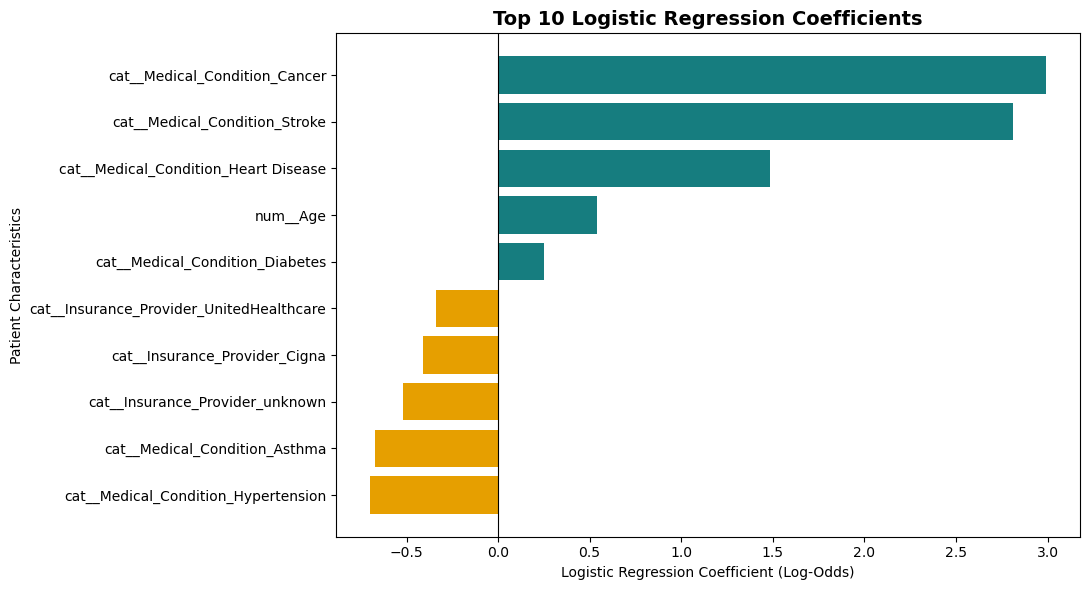

In [56]:

import matplotlib.pyplot as plt

plot_df = top_10_features.sort_values('Coefficient')

colors = ['#167D7F' if value >= 0 else '#E69F00'
          for value in plot_df['Coefficient']]

plt.figure(figsize=(11, 6))

plt.barh(
    plot_df['Feature'],
    plot_df['Coefficient'],
    color=colors
)

plt.axvline(0, color='black', linewidth=0.8)

plt.title('Top 10 Logistic Regression Coefficients',
          fontsize=14, fontweight='bold')

plt.xlabel('Logistic Regression Coefficient (Log-Odds)')
plt.ylabel('Patient Characteristics')

plt.tight_layout()
plt.show()


### Interpretation of Logistic Regression Coefficients

The Logistic Regression model identified Cancer (+2.99), Stroke (+2.81), and Heart Disease (+1.49) as the largest positive coefficients associated with high billing.

Hypertension (−0.70) and Asthma (−0.67) had negative coefficients, indicating lower predicted odds of high billing relative to their reference category, holding other variables constant.

The model achieved **68.89% accuracy**, outperforming the majority-class baseline of **51.85%**.

**Note:** Coefficients represent changes in log-odds, not direct changes in billing amounts. Age was standardized, while categorical variables were one-hot encoded, so coefficient magnitudes are not directly comparable across all features.

## Business Recommendations and Model Limitations

### Business Recommendations

Based on the Logistic Regression analysis, the following recommendations are proposed:

1. **Identify potential high-billing cases:** Healthcare analysts can investigate whether patient characteristics associated with high billing could support early financial planning.

2. **Improve resource planning:** Hospitals could explore how billing patterns relate to medical conditions when evaluating resource allocation and budgeting.

3. **Monitor billing trends:** Healthcare organizations should analyze billing patterns regularly to identify changes and opportunities for further investigation.

### Model Limitations

- **Model Accuracy:** The Logistic Regression model achieved 68.89% accuracy, compared with the majority-class baseline of 51.85%.
- **High-Billing Recall:** The model identified approximately 59% of actual high-billing cases, meaning some high-billing patients were incorrectly classified.
- **Limited Predictors:** The model used Age, Gender, Medical Condition, and Insurance Provider. Other factors may influence billing outcomes.
- **Dataset Limitations:** The analysis uses a practice dataset, so findings should not be assumed to represent actual hospital billing patterns.
- **Real-World Application:** The model requires further validation using representative real-world data before it could support operational decisions.

### Conclusion

The project demonstrates a complete machine-learning workflow, including data cleaning, preprocessing, Logistic Regression, model evaluation, and interpretation.

The model performed better than the majority-class baseline, but its moderate accuracy and limited high-billing recall indicate opportunities for improvement.

Future work could include additional relevant predictors, comparison with other classification algorithms, and further model validation.